<a href="https://colab.research.google.com/github/rabicenkonikita3-cloud/python-practice-algos/blob/student/hw_10_rabichenko_25_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [ ]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)
print('Train', len(train_data))
print('Test', len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 16.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 308kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.7MB/s]

Train 60000
Test 10000


In [ ]:
X_train = train_data.data.numpy().reshape(-1, 784) / 255.0
y_train = train_data.targets.numpy()

X_test = test_data.data.numpy().reshape(-1, 784) / 255.0
y_test = test_data.targets.numpy()

baseline = MLPClassifier(hidden_layer_sizes=(128,),
    max_iter=10,
    batch_size=64,
    random_state=42)

baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, pred)
print(f'Baseline accuracy: {baseline_acc:.3f}')

Baseline accuracy: 0.882


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
Baseline показал хорошую точность на Fashion-MNIST. Эта модель используется как исходный результат для сравнения с нейросетью на PyTorch.

In [ ]:
device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Устройство: cuda


In [ ]:
class Model1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10))
    def forward(self, x):
        return self.net(x)

class Model3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10))
    def forward(self, x):
        return self.net(x)


In [ ]:
model1 = Model1().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.parameters(), lr=0.001)
epochs = 10
losses1 = []
accs1 = []

for epoch in range(epochs):
    model1.train()
    loss_sum = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model1(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum +=loss.item()

    losses1.append(loss_sum / len(train_loader))

    model1.eval()
    correct = 0
    total=0
    with torch.no_grad():
        for x,y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model1(x)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    acc = correct / total
    accs1.append(acc)
    print(f'Epoch {epoch+1}: loss={losses1[-1]:.4f}, accuracy={acc:.4f}')

Epoch 1: loss=0.5504, accuracy=0.8416
Epoch 2: loss=0.3977, accuracy=0.8531
Epoch 3: loss=0.3585, accuracy=0.8669
Epoch 4: loss=0.3324, accuracy=0.8667
Epoch 5: loss=0.3124, accuracy=0.8702
Epoch 6: loss=0.2959, accuracy=0.8671
Epoch 7: loss=0.2820, accuracy=0.8757
Epoch 8: loss=0.2724, accuracy=0.8713
Epoch 9: loss=0.2632, accuracy=0.8807
Epoch 10: loss=0.2530, accuracy=0.8792


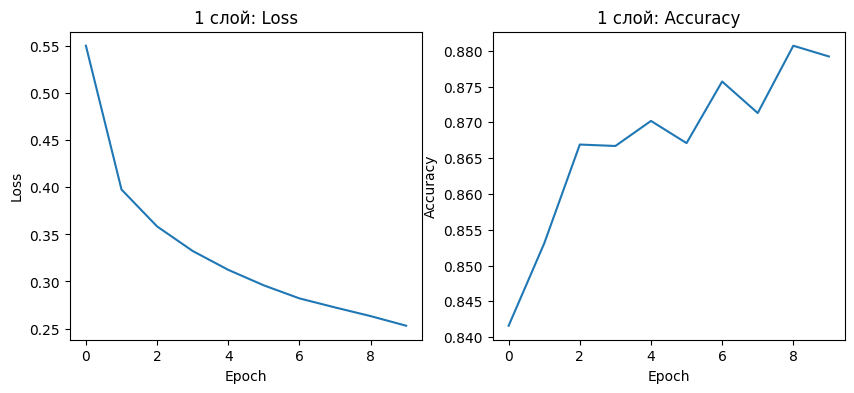

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(losses1)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('1 слой: Loss')

plt.subplot(1, 2, 2)
plt.plot(accs1)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('1 слой: Accuracy')

plt.show()

In [ ]:
class Model3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10))

    def forward(self, x):
        return self.net(x)

In [ ]:
model3 = Model3().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model3.parameters(),lr=0.001)
losses3 = []
accs3 = []

for epoch in range(epochs):
    model3.train()
    loss_sum = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model3(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()

    losses3.append(loss_sum /len(train_loader))
    model3.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in test_loader:
            x,y = x.to(device), y.to(device)
            out = model3(x)
            pred = out.argmax(dim=1)
            correct +=(pred == y).sum().item()
            total += y.size(0)

    acc= correct / total
    accs3.append(acc)
    print(f'Epoch {epoch+1}: loss={losses3[-1]:.4f}, accuracy={acc:.4f}')

Epoch 1: loss=0.5552, accuracy=0.8479
Epoch 2: loss=0.3799, accuracy=0.8583
Epoch 3: loss=0.3376, accuracy=0.8571
Epoch 4: loss=0.3128, accuracy=0.8633
Epoch 5: loss=0.2932, accuracy=0.8724
Epoch 6: loss=0.2787, accuracy=0.8759
Epoch 7: loss=0.2644, accuracy=0.8804
Epoch 8: loss=0.2547, accuracy=0.8850
Epoch 9: loss=0.2442, accuracy=0.8845
Epoch 10: loss=0.2316, accuracy=0.8872


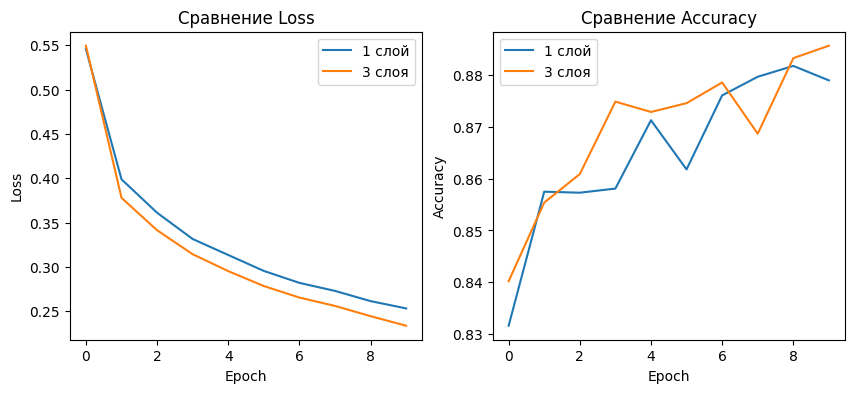

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(losses1, label='1 слой')
plt.plot(losses3, label='3 слоя')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Сравнение Loss')

plt.subplot(1, 2, 2)
plt.plot(accs1, label='1 слой')
plt.plot(accs3, label='3 слоя')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Сравнение Accuracy')
plt.show()

In [ ]:
Модель с тремя скрытыми слоями сложнее по архитоектуре и может находить более сложные зависимости в данных
По сравнению с моделью с одним слоем получается ее точность выше,а ошибка обучения снижается быстрее, увеличехние количества слоёв в данном случае улучшает качество модели

In [ ]:
class ModelBN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),
            nn.Linear(784, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 64),nn.ReLU(),
            nn.Linear(64, 10))
    def forward(self,  x):
        return self.net(x)

In [ ]:
model_bn = ModelBN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_bn.parameters(), lr=0.001)
loss_bn = []
acc_bn = []

for epoch in range(epochs):
    model_bn.train()
    loss_sum = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model_bn(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()

    loss_bn.append(loss_sum / len(train_loader))

    model_bn.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model_bn(x)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    acc = correct / total
    acc_bn.append(acc)
    print(f'Epoch {epoch+1}: loss={loss_bn[-1]:.4f}, accuracy={acc:.4f}')

Epoch 1: loss=0.6294, accuracy=0.8451
Epoch 2: loss=0.4762, accuracy=0.8548
Epoch 3: loss=0.4416, accuracy=0.8599
Epoch 4: loss=0.4164, accuracy=0.8649
Epoch 5: loss=0.4013, accuracy=0.8656
Epoch 6: loss=0.3896, accuracy=0.8682
Epoch 7: loss=0.3755, accuracy=0.8718
Epoch 8: loss=0.3669, accuracy=0.8757
Epoch 9: loss=0.3598, accuracy=0.8789
Epoch 10: loss=0.3501, accuracy=0.8767


In [ ]:
def train_model(model, optimizer, epochs=10):
    criterion = nn.CrossEntropyLoss()
    losses = []
    accuracies = []

    for epoch in range(epochs):
        model.train()
        loss_sum = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item()

        losses.append(loss_sum / len(train_loader))

        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)

                out = model(x)
                pred = out.argmax(dim=1)

                correct += (pred == y).sum().item()
                total += y.size(0)

        accuracies.append(correct / total)

    return losses, accuracies

In [ ]:
model_sgd = ModelBN().to(device)
optimizer_sgd = optim.SGD(model_sgd.parameters(),lr=0.01,momentum=0.9)
loss_sgd,acc_sgd =train_model(model_sgd,
    optimizer_sgd)

model_adam = ModelBN().to(device)
optimizer_adam =optim.Adam(model_adam.parameters(),lr=0.001)
loss_adam, acc_adam = train_model(model_adam,optimizer_adam)

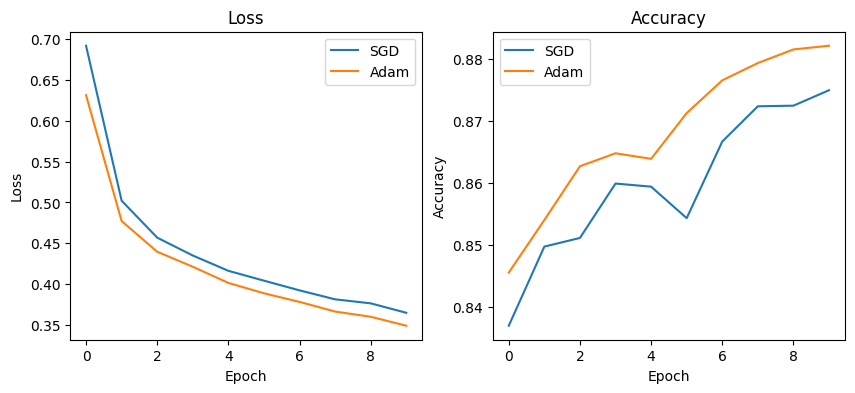

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_sgd, label='SGD')
plt.plot(loss_adam, label='Adam')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(acc_sgd, label='SGD')
plt.plot(acc_adam, label='Adam')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy')

plt.show()

In [ ]:
Adam сходится быстрее, чем SGD с моментом, наверное потому чтоо автоматически подстраивает шаг обучения для разных параметров
SGD обучается сииииильно медленнее, но если правилшьный learning rate то показывает хороший результат

In [ ]:
learning_rates = [0.1, 0.01,0.001, 0.0001]
lr_losses = {}
lr_accs = {}
for lr in learning_rates:
    model = ModelBN().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses, accs = train_model(model, optimizer, epochs=6)
    lr_losses[lr] = losses
    lr_accs[lr] = accs
    print(f'Готово для lr={lr}, точность: {accs[-1]:.4f}')



Готово для lr=0.1, точность: 0.7274
Готово для lr=0.01, точность: 0.8622
Готово для lr=0.001, точность: 0.8679
Готово для lr=0.0001, точность: 0.8642


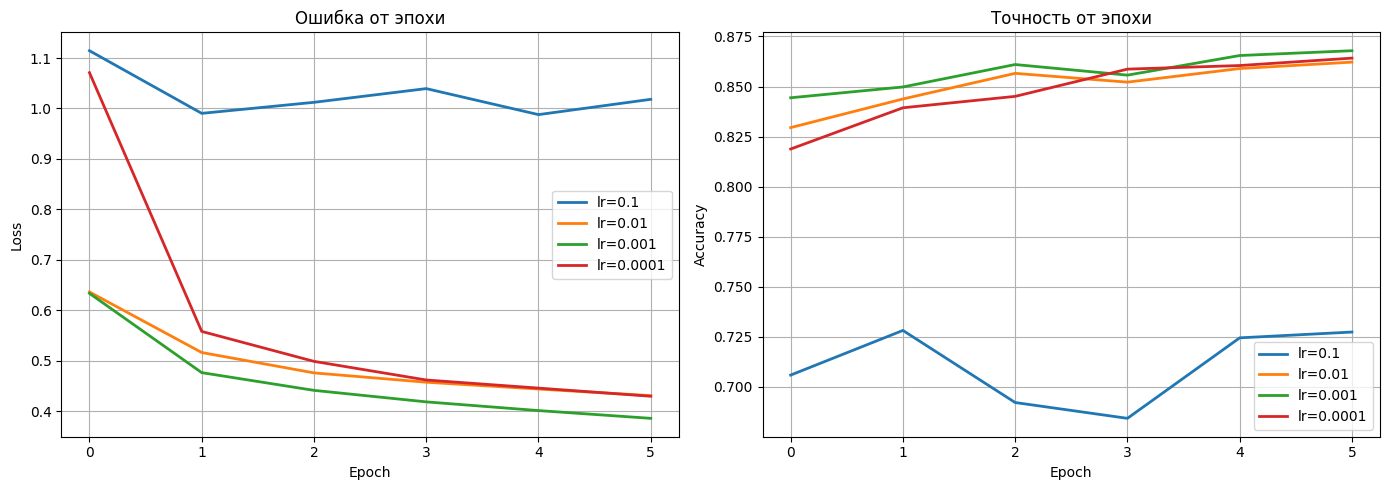

In [ ]:
fig, axes =plt.subplots(1,2,figsize=(14,5))

for lr in learning_rates:
    axes[0].plot(lr_losses[lr], label=f'lr={lr}', linewidth=2)
axes[0].set_title('Ошибка от эпохи')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

for lr in learning_rates:
    axes[1].plot(lr_accs[lr], label=f'lr={lr}', linewidth=2)
axes[1].set_title('Точность от эпохи')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
При большом learning rate обучение может проходить нестабильно, потому что веса меняются слишком сильно на каждом шаге
При lr=0.01 модель обычно обучается быстрее и при этом достазточно стабильно
При lr=0.001 обучение проходит более спокойно и обычно даёт хороший результат
При lr =0.0001 обучение идёт медленшнее, так как изменения весов на каждом шаге небольшие

В итоге можно сказать, что слишком большой шаг обучения  может мешать нормальной работе модели, а слишком маленький делает его слишком медленным
Поэтому лучше выбирать значение, где модель достаточно быстро обучается и не теряет качество. В нашем случае это видно по графикам.